# Exploring sizes of discovered exoplanets over time
Adam Noonan | C00299231

## Introduction

I wanted to know whether newly discovered exoplanets are getting smaller over time. To answer this, I built a linear regression model that predicts a planet's radius from its discovery year & method.

This matters because telescopes and techniques have changed over time, so planets found may not represent the planets that exist outside our solar system.

If the typical discovered planet is shrinking, it can mean our current understanding of planets is incomplete and will be refined with further developments in discovery techniques.

## Data
The selected dataset comes from the NASA exoplanet archive, using the planetary systems composite parameters table (pscommpars), downloaded on 2026-10-15. It contains 6,445 confirmed planets and originally 703 columns. I kept 23 columns including details about systems, discovery details, planet details, star details, etc. The other columns were dropped, mostly including error bars, limit flags, etc.

I first used a copy of this data sourced from Kaggle, but this was a cut down version of the original dataset which did not exactly fit my use case, so I moved to the original source and chose my own columns to keep.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

filename = r"exoplanets_slim_2026-10-15.csv"

df = pd.read_csv(
    filename,
    header=0
)

# making columns titles more readable
df = df.rename(columns={
    "pl_name": "pl_name",
    "hostname": "host_name",

    "sy_snum": "sys_num_star",
    "sy_pnum": "sys_num_planet",
    "sy_dist": "sys_dist_e",

    "discoverymethod": "disc_method",
    #"disc_year": "",
    #"disc_facility": "",

    #"pl_controv_flag": "",
    "pl_eqt": "pl_temp",
    "pl_insol": "pl_insol_flux",

    "pl_orbper": "pl_orb_period",
    "pl_orbeccen": "pl_orb_eccen",
    "pl_orbsmax": "pl_orb_semimajor_axis",

    "pl_rade": "pl_radius_e",
    "pl_bmasse": "pl_mass_e",
    "pl_bmassprov": "pl_mass_prov",

    "st_teff": "st_temp",
    "st_rad": "st_radius",
    #"st_mass": "",
    "st_met": "st_metal",
    "st_logg": "st_gravity",
    #"st_age": "",
    })

print(df.shape)
display(df.dtypes)

(6445, 22)


pl_name                      str
host_name                    str
sys_num_star               int64
sys_num_planet             int64
sys_dist_e               float64
disc_method                  str
disc_year                  int64
disc_facility                str
pl_controv_flag            int64
pl_temp                  float64
pl_insol_flux            float64
pl_orb_eccen             float64
pl_orb_semimajor_axis    float64
pl_radius_e              float64
pl_mass_e                float64
pl_mass_prov                 str
st_temp                  float64
st_radius                float64
st_mass                  float64
st_metal                 float64
st_gravity               float64
st_age                   float64
dtype: object

## Preprocessing
- **Missing Values:** I dropped rows missing planet radius, discovery year or discovery method. This removed 50 entries from the dataset.
- **Log Transform:** Planet radius ranges from under 0.5 to about 80 Earth radii and is heavily skewed, with most planets being small. I took the base-10 log of radius so a few giant planets do not dominate the fit, and changes can be read as multiplicative.

In [2]:
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

d = df.dropna(subset=["pl_radius_e", "disc_year", "disc_method"]).copy()
d["log_radius_e"] = np.log10(d["pl_radius_e"])

print("dropped rows: ", len(df) - len(d))
print(d["log_radius_e"].describe())
print(d["disc_method"].value_counts())

dropped rows:  50
count    6395.000000
mean        0.582134
std         0.403860
min        -0.508919
25%         0.267172
50%         0.456366
75%         1.075547
max         1.940546
Name: log_radius_e, dtype: float64
disc_method
Transit                          4780
Radial Velocity                  1166
Microlensing                      292
Imaging                            93
Transit Timing Variations          28
Eclipse Timing Variations          15
Pulsar Timing                       6
Astrometry                          6
Orbital Brightness Modulation       6
Pulsation Timing Variations         2
Disk Kinematics                     1
Name: count, dtype: int64


In [3]:
x = d[["disc_year"]]
y = d["log_radius_e"]

xTrain, xTest, yTrain, yTest = train_test_split(
    x, y, test_size=0.2, random_state=42
)

m1 = LinearRegression().fit(xTrain, yTrain)

## Regression

I trained a model on the discovery year and log radius, splitting the data 80/20 into training and test sets. The model was trained on the training set, and scored on the test set so scores reflect data the model has never seen

I ran cross-validation on the training set to check the results were stable. My model is scored with two metrics:

- R^2 is how much of the data variation can be explained by the model. 0 is no better than guessing, and 1 is a perfect fit.
- RMSE is the typical size of the model's error. An RMSE of X means the model's predicitons are typically off by a factor of 10^X.

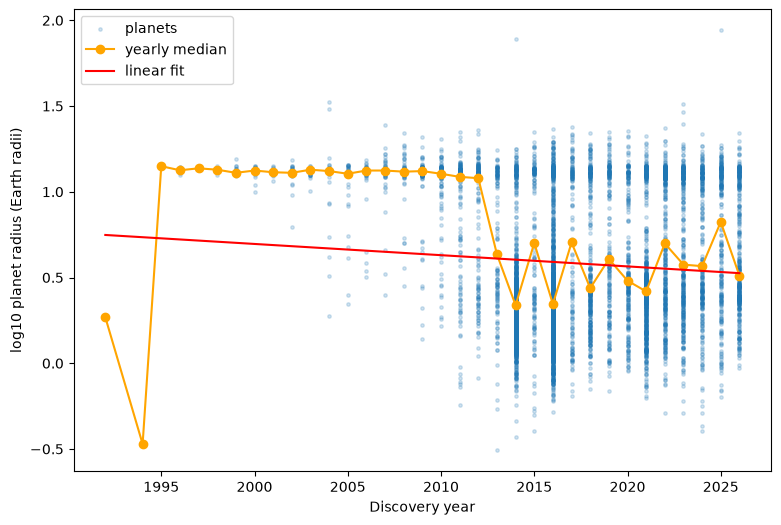

In [4]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(d["disc_year"], d["log_radius_e"], s=6, alpha=0.2, label="planets")

med = d.groupby("disc_year")["log_radius_e"].median()
ax.plot(med.index, med.values, "o-", color="orange", label="yearly median")

xs = np.linspace(d["disc_year"].min(), d["disc_year"].max(), 100)
ax.plot(xs, m1.predict(pd.DataFrame({"disc_year": xs})), "r", label="linear fit")

ax.set_xlabel("Discovery year")
ax.set_ylabel("log10 planet radius (Earth radii)")
ax.legend()
plt.show()

In [14]:
pred1 = m1.predict(xTest)
print("slope:", m1.coef_[0], "intercept:", m1.intercept_)
print("test R^2:", r2_score(yTest, pred1))
print("test RMSE:", np.sqrt(mean_squared_error(yTest, pred1)))
print("typical radius changes by factor of", 10 ** m1.coef_[0], "each year")

slope: -0.006549232512435148 intercept: 13.794154966295093
test R^2: 0.01880403649349316
test RMSE: 0.40504978175684275
typical radius changes by factor of 0.98503297111833 each year


In [ ]:
baseline = np.full(len(yTest), yTrain.mean())
baseline_rmse = np.sqrt(mean_squared_error(yTest, baseline))
print("BASELINE: ". baseline_rmse)

0.4089284847882988
2.564061778057038


## Results and Conclusion

R^2 is 0.019 and RMSE is 0.405.

Baseline RMSE is 0.409, meaning the model is only slightly more accurate than guessing.

My thoughts are that radii of detected planets are not necessarily dependent on discovery year, rather discovery method. In our graph we see a dip in yearly median starting from around 2010, the year after the Kepler space telescope was launched to discover earth-sized exoplanets.

By factoring in the discovery method I could perhaps create a more accurate model, but I think with this model I can say its unlikely that discovery year has a substantial correlation to shrinking radii of newly discovered planets.